In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot-only notebook: the numbers are produced by `python postprocess.py` (-> ./data/*.csv)
os.makedirs('../plots', exist_ok=True)

In [2]:
import re
import matplotlib.pyplot as plt
import seaborn as sns

def plot_acc_noise(
    noise_levels,
    accuracies,
    labels,
    xlabel=r'$\sigma$',
    ylabel='Model Accuracy',
    title='',
    figsize=(13, 8),
    fontsize=25,
    linewidth=4.0,
    markersize=18,
    legend_loc="best",
    legend_framealpha=0.95,
    savepath="../plots/noise_exp.pdf",
    baseline_acc=0.8445,
    baseline_label='Baseline',
    baseline_linestyle='--',
    baseline_color='black',
    random_acc=0.10,
    random_label='Random',
    random_linestyle='-.',
    random_color='gray'
):
    """
    Sort legend/lines by number of traces.
    HW and HD with the same trace count get the same color,
    but different linestyle and marker.
    """
    sns.set(style="whitegrid")
    fig, ax = plt.subplots(figsize=figsize)

    n = len(labels)
    if not (len(noise_levels) == len(accuracies) == n):
        raise ValueError("noise_levels, accuracies, labels must have the same length")

    def parse_label(label):
        """
        Expected labels like:
        '200 HW', '200 HD', '400 HW', '400 HD'
        """
        m = re.search(r'(\d+)', label)
        trace_num = int(m.group(1)) if m else float("inf")

        leakage = "HW" if "HW" in label.upper() else "HD" if "HD" in label.upper() else ""

        return trace_num, leakage

    # Sort by number of traces, then HW before HD
    order = sorted(
        range(n),
        key=lambda i: (parse_label(labels[i])[0], parse_label(labels[i])[1] == "HW")
    )

    # One color per trace number
    trace_nums = sorted(set(parse_label(labels[i])[0] for i in range(n)))
    color_palette = sns.color_palette(n_colors=len(trace_nums))
    color_by_trace = {
        trace_num: color_palette[j]
        for j, trace_num in enumerate(trace_nums)
    }

    linestyle_by_type = {
        "HW": "-",
        "HD": "--"
    }

    marker_by_type = {
        "HW": "o",
        "HD": "s"
    }

    # Baseline first
    ax.axhline(
        y=baseline_acc,
        linestyle=baseline_linestyle,
        color=baseline_color,
        linewidth=2.5,
        label=baseline_label
    )
    # Random baseline last
    ax.axhline(
        y=random_acc,
        linestyle=random_linestyle,
        color=random_color,
        linewidth=2.5,
        label=random_label
    )

    # Plot sorted series
    for i in order:
        xs = noise_levels[i]
        ys = accuracies[i]
        lab = labels[i]

        trace_num, leakage = parse_label(lab)

        ax.plot(
            xs, ys,
            marker=marker_by_type.get(leakage, "o"),
            linestyle=linestyle_by_type.get(leakage, "-"),
            color=color_by_trace[trace_num],
            linewidth=linewidth,
            markersize=markersize,
            label=lab,
            alpha=0.95
        )

    

    ax.set_xlabel(xlabel, fontsize=fontsize)
    ax.set_ylabel(ylabel, fontsize=fontsize)
    ax.set_title(title, fontsize=fontsize)
    ax.tick_params(axis='both', labelsize=fontsize)
    ax.set_ylim(0, 1.05)
    ax.grid(True)

    ax.legend(

    fontsize=fontsize - 5,

    loc="upper right",

    bbox_to_anchor=(1, 1),

    borderaxespad=0.0,

    framealpha=legend_framealpha,
        ncol=4
    )

    plt.tight_layout()
    fig.savefig(
        savepath,
        format="pdf",
        bbox_inches="tight",
        metadata={"Creator": "Matplotlib"}
    )
    plt.show()

    return fig, ax

In [3]:
df = pd.read_csv('data/noise_ext_comp.csv')
acc_tbl = df.set_index(['leakage', 'traces_k', 'sigma'])

In [4]:
specs = [
    {"label": "200k HD", "trace_k": 200, "leakage": "HD", "noises": [4, 6, 10, 12, 14, 16]},
    {"label": "200k HW", "trace_k": 200, "leakage": "HW", "noises": [4, 6, 10, 12, 14, 16]},
    {"label": "400k HD", "trace_k": 400, "leakage": "HD", "noises": [4, 6, 10, 12, 14, 16]},
    {"label": "400k HW", "trace_k": 400, "leakage": "HW", "noises": [4, 6, 10, 12, 14, 16]},
    {"label": "800k HD", "trace_k": 800, "leakage": "HD", "noises": [4, 6, 10, 12, 14, 16]},
    {"label": "800k HW", "trace_k": 800, "leakage": "HW", "noises": [8, 10, 12, 14]},
]

In [5]:
# Build the exact structures your plot expects:
noises = [s["noises"] for s in specs]
acc = [[acc_tbl.loc[(s["leakage"], s["trace_k"], n), 'acc_raw'] for n in s["noises"]] for s in specs]
labels = [s["label"] for s in specs]

In [6]:
labels

['200k HD', '200k HW', '400k HD', '400k HW', '800k HD', '800k HW']

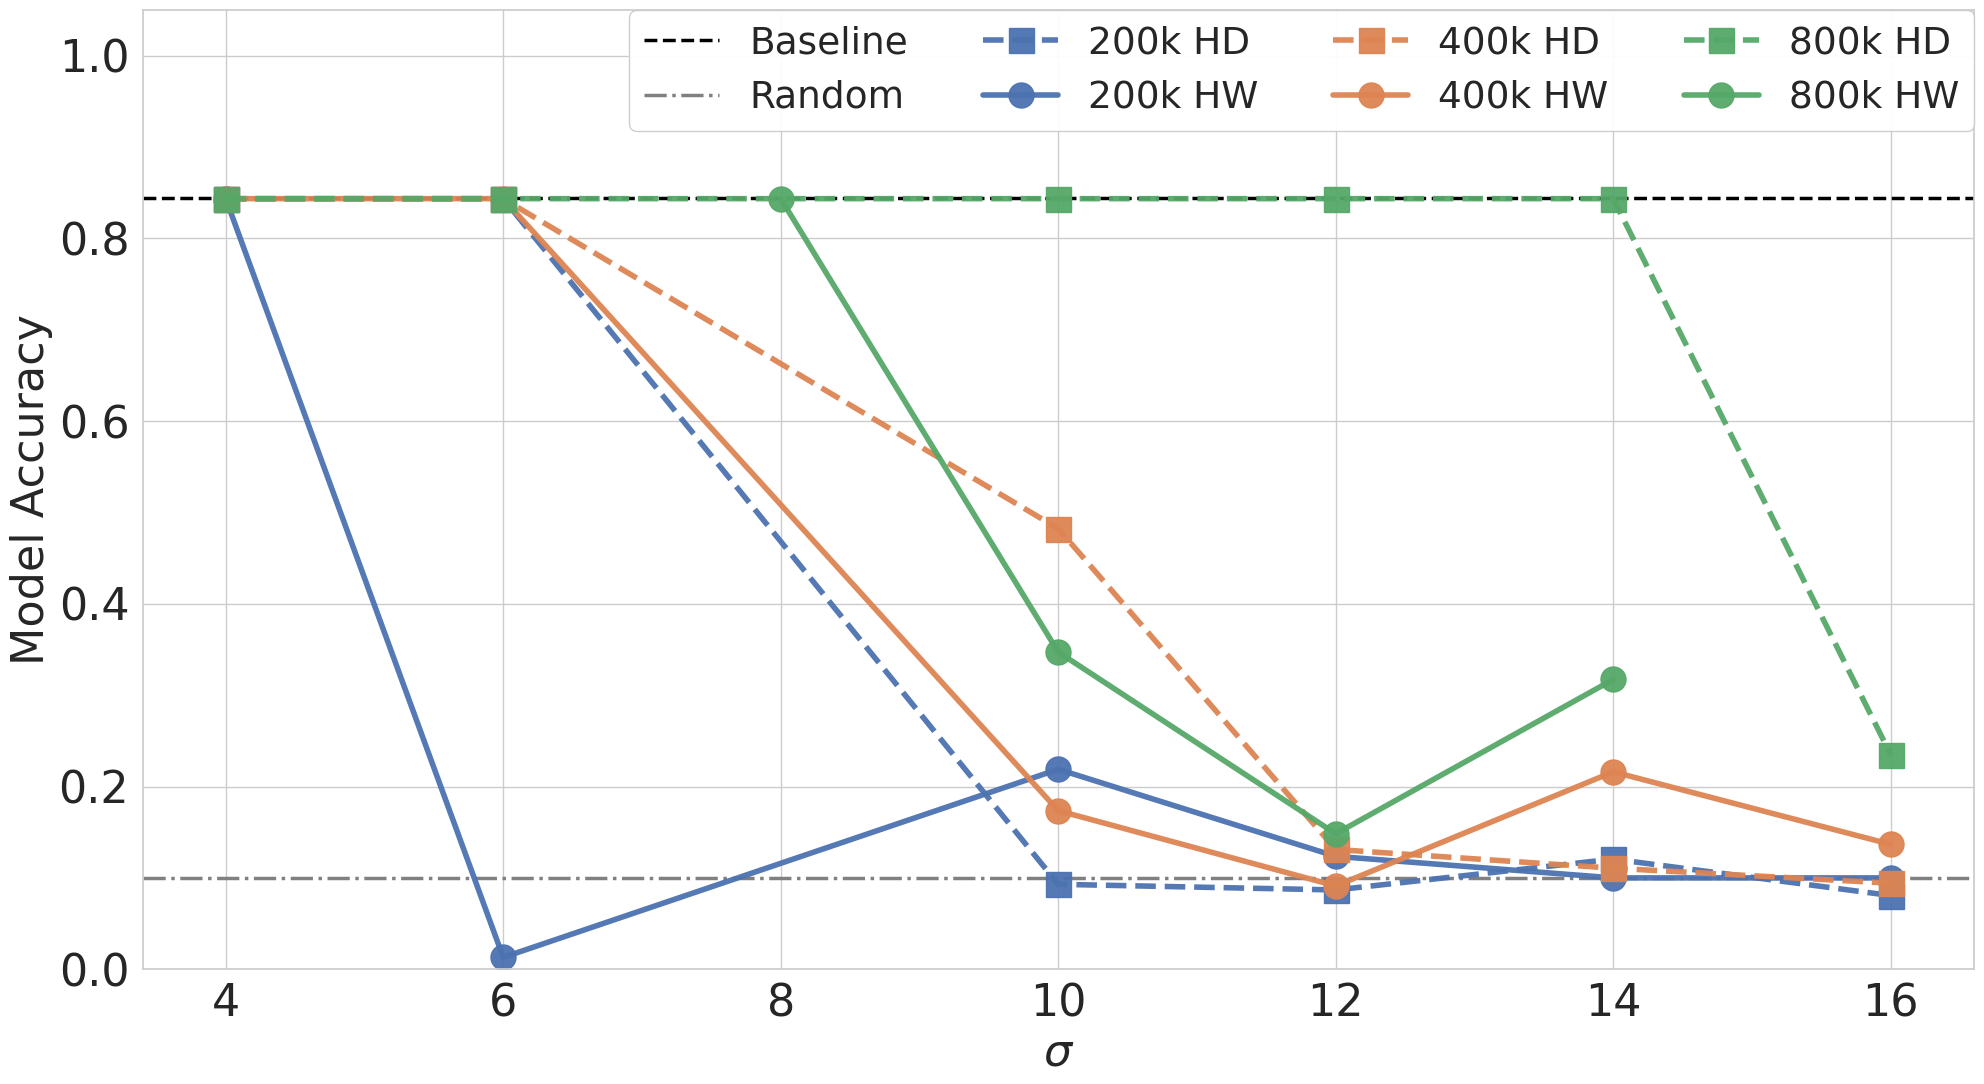

(<Figure size 2000x1100 with 1 Axes>,
 <Axes: xlabel='$\\sigma$', ylabel='Model Accuracy'>)

In [7]:
plot_acc_noise(noises, acc, labels , figsize=(20, 11), fontsize=32)

In [8]:
# after the sign-flip fix of the last layer, see postprocess.sign_fix
noises = [s["noises"] for s in specs]
acc = [[acc_tbl.loc[(s["leakage"], s["trace_k"], n), 'acc_sign_fixed'] for n in s["noises"]] for s in specs]
labels = [s["label"] for s in specs]

In [9]:
labels

['200k HD', '200k HW', '400k HD', '400k HW', '800k HD', '800k HW']

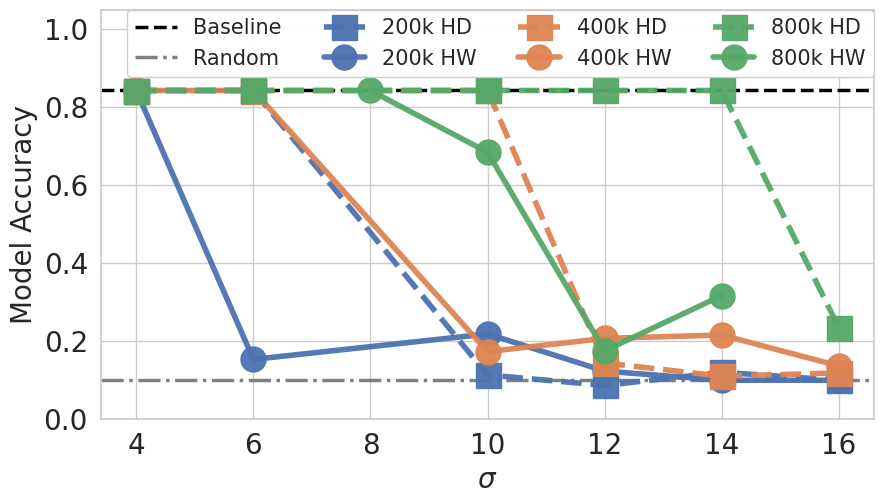

(<Figure size 900x520 with 1 Axes>,
 <Axes: xlabel='$\\sigma$', ylabel='Model Accuracy'>)

In [10]:
plot_acc_noise(noises, acc, labels, figsize=(9, 5.2), fontsize=20)